<a href="https://colab.research.google.com/github/Ashishjoshi794/heart-disease-prediction/blob/main/heart_disease_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
path = "/content/drive/MyDrive/heart_disease_dataset.csv"
df = pd.read_csv(path)

In [9]:
print(df.shape)

(1000, 16)


In [10]:
df.head()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
0,75,Female,228,119,66,Current,Heavy,1,No,No,Yes,8,119,Yes,Atypical Angina,1
1,48,Male,204,165,62,Current,NaN,5,No,No,No,9,70,Yes,Typical Angina,0
2,53,Male,234,91,67,Never,Heavy,3,Yes,No,Yes,5,196,Yes,Atypical Angina,1
3,69,Female,192,90,72,Current,NaN,4,No,Yes,No,7,107,Yes,Non-anginal Pain,0
4,62,Female,172,163,93,Never,NaN,6,No,Yes,No,2,183,Yes,Asymptomatic,0


In [11]:
df.sample(5)

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
440,25,Male,268,155,64,Current,NaN,9,No,Yes,Yes,6,89,Yes,Asymptomatic,0
152,76,Female,347,116,69,Current,Heavy,5,Yes,Yes,No,6,149,Yes,Asymptomatic,1
931,76,Female,309,116,70,Never,NaN,8,Yes,Yes,No,7,191,No,Typical Angina,1
509,38,Male,245,119,80,Never,Moderate,7,Yes,No,No,10,192,Yes,Atypical Angina,0
310,41,Female,289,125,76,Current,Moderate,9,No,Yes,Yes,5,110,No,Non-anginal Pain,0


In [12]:
df.shape

(1000, 16)

In [13]:
df.columns

Index(['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate',
       'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History',
       'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar',
       'Exercise Induced Angina', 'Chest Pain Type', 'Heart Disease'],
      dtype='object')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      1000 non-null   int64 
 1   Gender                   1000 non-null   object
 2   Cholesterol              1000 non-null   int64 
 3   Blood Pressure           1000 non-null   int64 
 4   Heart Rate               1000 non-null   int64 
 5   Smoking                  1000 non-null   object
 6   Alcohol Intake           660 non-null    object
 7   Exercise Hours           1000 non-null   int64 
 8   Family History           1000 non-null   object
 9   Diabetes                 1000 non-null   object
 10  Obesity                  1000 non-null   object
 11  Stress Level             1000 non-null   int64 
 12  Blood Sugar              1000 non-null   int64 
 13  Exercise Induced Angina  1000 non-null   object
 14  Chest Pain Type          1000 non-null   

In [15]:
df.dtypes.value_counts()

,count
int64,8
object,8


In [16]:
df.describe()

,Age,Cholesterol,Blood Pressure,Heart Rate,Exercise Hours,Stress Level,Blood Sugar,Heart Disease
count,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,52.293000,249.939000,135.2810,79.204000,4.529000,5.646000,134.941000,0.392000
std,15.727126,57.914673,26.3883,11.486092,2.934241,2.831024,36.699624,0.488441
min,25.000000,150.000000,90.0000,60.000000,0.000000,1.000000,70.000000,0.000000
25%,39.000000,200.000000,112.7500,70.000000,2.000000,3.000000,104.000000,0.000000
50%,52.000000,248.000000,136.0000,79.000000,4.500000,6.000000,135.000000,0.000000
75%,66.000000,299.000000,159.0000,89.000000,7.000000,8.000000,167.000000,1.000000
max,79.000000,349.000000,179.0000,99.000000,9.000000,10.000000,199.000000,1.000000


In [17]:
df.isnull().sum()

,0
Age,0
Gender,0
Cholesterol,0
Blood Pressure,0
Heart Rate,0
Smoking,0
Alcohol Intake,340
Exercise Hours,0
Family History,0
Diabetes,0


In [18]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
995,False
996,False
997,False
998,False


In [19]:
# Check duplicate records

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [20]:
df['Heart Disease'].value_counts()

,count
Heart Disease,
0,608
1,392



**Heart disease patient = 392**

**Non Heard disease patient = 608**

In [21]:
youngest_age = df['Age'].min()
oldest_age = df['Age'].max()
age_range = oldest_age - youngest_age
print(f"Youngest Age = {youngest_age}")
print(f"Oldest Age = {oldest_age}")
print(f"Range of Age = {oldest_age - youngest_age}")

Youngest Age = 25
Oldest Age = 79
Range of Age = 54


In [22]:

df['Alcohol Intake'].value_counts()

,count
Alcohol Intake,
Heavy,346
Moderate,314



Alcohol Intake column have 340 missing valuse which is about one third of our dataset. so dropping is recommended.

It is categorical column so so we can not find the mean or median to fill missing value.

Most of the people do not drink so we will fill the missing value with 'Never'

In [23]:
df['Alcohol Intake'].fillna('Never', inplace=True)

/tmp/ipykernel_1470/1379622639.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Alcohol Intake'].fillna('Never', inplace=True)


In [24]:
df.isnull().sum()

,0
Age,0
Gender,0
Cholesterol,0
Blood Pressure,0
Heart Rate,0
Smoking,0
Alcohol Intake,0
Exercise Hours,0
Family History,0
Diabetes,0


In [25]:
df['Alcohol Intake'].value_counts()

,count
Alcohol Intake,
Heavy,346
Never,340
Moderate,314


Check for any impossible or suspicious values in numerical columns (e.g. Cholesterol = 0, Heart Rate = 0).

In [26]:
print("Impossible values in age = ",(df['Age']==0).sum())
print("Impossible value in Cholesterol = ",(df['Cholesterol']==0).sum())
print("Impossible values in Blood Pressure  =",(df['Blood Pressure']==0).sum())
print("impossible values in Heart Rate = ",(df['Heart Rate']==0).sum())
print("impossible values in Blood sugar = ",(df['Blood Sugar']==0).sum())

Impossible values in age =  0
Impossible value in Cholesterol =  0
Impossible values in Blood Pressure  = 0
impossible values in Heart Rate =  0
impossible values in Blood sugar =  0



No any impossible or suspicious values in numerical columns like Age, Cholesterol, Blood Pressure, Heart Rate, Blood sugar

In [27]:
df['Heart Disease'].map({0: 'No', 1: 'Yes'})

,Heart Disease
0,Yes
1,No
2,Yes
3,No
4,No
...,...
995,Yes
996,Yes
997,No
998,Yes


In [28]:
df['Heart Disease']=df['Heart Disease'].map({0: 'No', 1: 'Yes'})

In [29]:
df.sample()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
7,60,Female,208,148,83,Never,Moderate,4,No,Yes,Yes,2,113,Yes,Asymptomatic,Yes


In [30]:
# function to check and handle outliers

def handle_outliers_with_median(df, column_name):
    # 1. Calculate IQR statistics using clean, local variable names
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1

    # 2. Define bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # 3. Find and count outliers
    outliers_mask = (df[column_name] < lower_bound) | (df[column_name] > upper_bound)
    outlier_count = outliers_mask.sum()
    print(f"Found {outlier_count} outliers in '{column_name}'")

    # 4. Replace outliers with the column median
    median_val = df[column_name].median()
    df.loc[outliers_mask, column_name] = median_val

    return df

In [31]:

df = handle_outliers_with_median(df,'Cholesterol')
df = handle_outliers_with_median(df,'Blood Sugar')
df = handle_outliers_with_median(df,'Heart Rate')

Found 0 outliers in 'Cholesterol'
Found 0 outliers in 'Blood Sugar'
Found 0 outliers in 'Heart Rate'


Create a new column Age_Group — Young (25–40), Middle-Aged (41–60), Senior (61–79).

In [32]:
df.loc[((df['Age']>=25) & (df['Age']<=40)),'Age_Group'] = 'Young'
df.loc[((df['Age']>=41) & (df['Age']<=60)),'Age_Group'] = 'Middle-Aged'
df.loc[(df['Age']>=61) & (df['Age']<=79),'Age_Group'] = 'Senior'

In [33]:

df['Age_Group'].value_counts()

,count
Age_Group,
Middle-Aged,372
Senior,353
Young,275


Create a new column Cholesterol_Category — Normal (<200), Borderline (200–239), High (≥240).

In [34]:
# df.loc[condition,'column_name'] = "catagory_name"
df.loc[(df['Cholesterol']<200),'Cholesterol_Category'] = 'Normal'
df.loc[(df['Cholesterol']>=200) & (df['Cholesterol']<=239), 'Cholesterol_Category'] = 'Borderline'
df.loc[(df['Cholesterol']>=240),'Cholesterol_Category'] = 'High'

In [35]:

df['Cholesterol_Category'].value_counts()

,count
Cholesterol_Category,
High,550
Normal,246
Borderline,204


Create a new column BP_Category — Normal (<120), Elevated (120–129), High (≥130).

In [36]:
df.loc[(df['Blood Pressure']<120),'BP_Category'] = 'Normal'
df.loc[(df['Blood Pressure']>=120) & (df['Blood Pressure']<=129),'BP_Category'] = 'Elevated'
df.loc[(df['Blood Pressure']>=130), 'BP_Category'] = 'High'

In [37]:
df['BP_Category'].value_counts()

,count
BP_Category,
High,571
Normal,333
Elevated,96


**Data Manipulation**

In [38]:
# Show only the rows where Heart Disease is Yes
heart_disease_patients = df[df['Heart Disease'] == 'Yes']

# Display first 5 rows
heart_disease_patients.head()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease,Age_Group,Cholesterol_Category,BP_Category
0,75,Female,228,119,66,Current,Heavy,1,No,No,Yes,8,119,Yes,Atypical Angina,Yes,Senior,Borderline,Normal
2,53,Male,234,91,67,Never,Heavy,3,Yes,No,Yes,5,196,Yes,Atypical Angina,Yes,Middle-Aged,Borderline,Normal
5,77,Male,309,110,73,Never,Never,0,No,Yes,Yes,4,122,Yes,Asymptomatic,Yes,Senior,High,Normal
6,64,Female,211,105,86,Former,Heavy,8,Yes,Yes,Yes,2,120,No,Typical Angina,Yes,Senior,Borderline,Normal
7,60,Female,208,148,83,Never,Moderate,4,No,Yes,Yes,2,113,Yes,Asymptomatic,Yes,Middle-Aged,Borderline,High


In [40]:
# Show only the rows where Heart Disease is No
no_heart_disease_patients = df[df['Heart Disease'] == 'No']

# Display first 5 rows
no_heart_disease_patients.head()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease,Age_Group,Cholesterol_Category,BP_Category
1,48,Male,204,165,62,Current,Never,5,No,No,No,9,70,Yes,Typical Angina,No,Middle-Aged,Borderline,High
3,69,Female,192,90,72,Current,Never,4,No,Yes,No,7,107,Yes,Non-anginal Pain,No,Senior,Normal,Normal
4,62,Female,172,163,93,Never,Never,6,No,Yes,No,2,183,Yes,Asymptomatic,No,Senior,Normal,High
8,37,Female,317,137,66,Current,Heavy,3,No,Yes,Yes,5,114,No,Non-anginal Pain,No,Young,High,High
11,37,Male,293,148,98,Current,Moderate,6,Yes,No,Yes,10,129,No,Typical Angina,No,Young,High,High


In [41]:
# Sort rows by Age in ascending order
df_sorted_age = df.sort_values(by='Age', ascending=True)

df_sorted_age[['Age', 'Gender', 'Heart Disease']].head(10)

,Age,Gender,Heart Disease
54,25,Female,No
259,25,Female,No
68,25,Female,No
440,25,Male,No
467,25,Female,No
766,25,Male,No
298,25,Female,No
752,25,Male,No
130,25,Male,No
714,25,Male,No


In [42]:
# Count the number of people in each age group
age_group_count = df['Age_Group'].value_counts()

print(age_group_count)

Age_Group
Middle-Aged    372
Senior         353
Young          275
Name: count, dtype: int64


In [43]:
# Compare average numerical values for No and Yes groups
df.groupby('Heart Disease')[[
    'Age',
    'Cholesterol',
    'Blood Pressure',
    'Heart Rate',
    'Exercise Hours',
    'Stress Level',
    'Blood Sugar'
]].mean()

,Age,Cholesterol,Blood Pressure,Heart Rate,Exercise Hours,Stress Level,Blood Sugar
Heart Disease,,,,,,,
No,44.128289,232.972039,135.134868,79.082237,4.562500,5.629934,135.324013
Yes,64.956633,276.255102,135.507653,79.392857,4.477041,5.670918,134.346939


In [44]:
# Create a table showing Gender against Heart Disease
gender_heart_disease = pd.crosstab(df['Gender'], df['Heart Disease'])

gender_heart_disease

Heart Disease,No,Yes
Gender,,
Female,313,190
Male,295,202


In [45]:
# Create a table showing Smoking status against Heart Disease
smoking_heart_disease = pd.crosstab(df['Smoking'], df['Heart Disease'])

smoking_heart_disease

Heart Disease,No,Yes
Smoking,,
Current,194,142
Former,219,107
Never,195,143


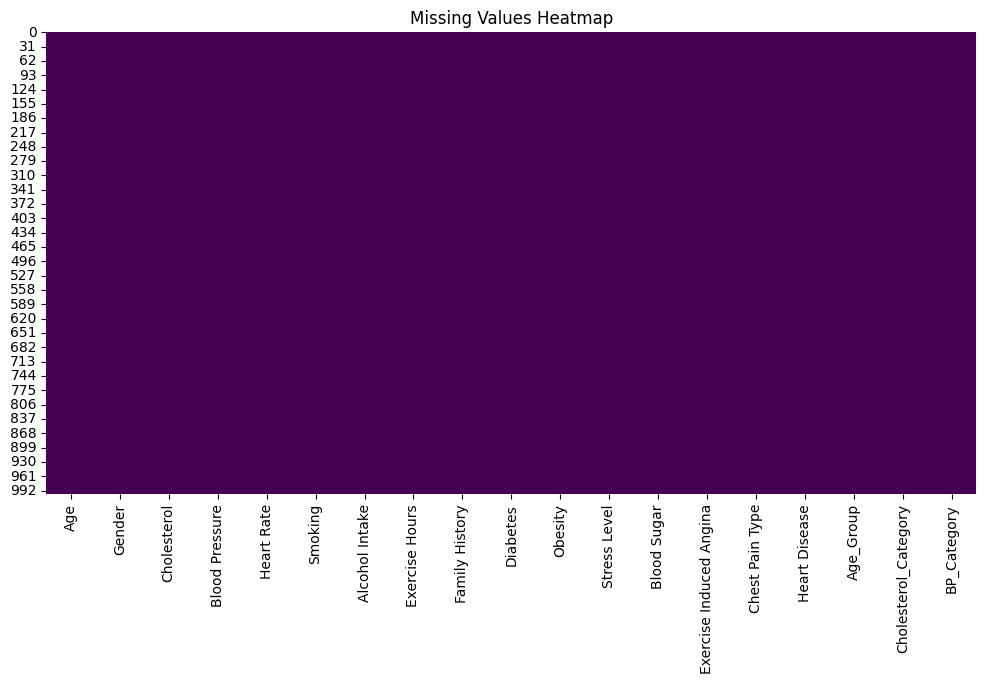

In [39]:
# Visualize missing values

plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Missing Values Heatmap")
plt.show()